# 🏠 DS-29: California Housing — Çoklu Lineer Regresyon & Multicollinearity
**Modül:** ML-02 (Regresyon) • Part 1568-1570 + 1631

Bu notebook'ta **DS-29 ödevindeki 10 sorunun her biri** hem teorik temelleriyle hem de çalıştırılabilir kodlarıyla adım adım incelenmiştir.

### Konu Başlıkları:
1. `load_california_data`: Veri setini çekme ve yapılandırma
2. `split_and_scale`: Data Leakage olmadan train/test ayrımı ve StandardScaler
3. `train_linear_model`: En Küçük Kareler (OLS) ile model eğitimi
4. `evaluate_model`: Regresyon metrikleri (MAE, RMSE, R²)
5. `analyze_coefficients`: Standartlaştırılmış katsayılar ve özellik önemi
6. `find_correlated_pairs`: Çoklu doğrusallık tespiti (Üst üçgen korelasyon matrisi)
7. `calculate_vif`: Manuel Varyans Artış Faktörü (VIF) hesabı
8. `engineer_bedrms_per_room`: Oran (ratio) mühendisliği ile çoklu doğrusallık çözümü
9. `predict_house_price`: Production için tekil gözlem tahmini
10. `run_full_pipeline`: Uçtan uca orkestrasyon


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


---
## Soru 1: California Housing Veri Setini Yükleme (`load_california_data`)

### 🧠 Teori ve Mantık:
California Housing veri seti, 1990 nüfus sayımı verilerine dayanan 20.640 mahalle blok grubunu ve 8 özelliği içerir:
- `MedInc`: Mahallenin medyan geliri (10.000$ biriminde) - En kritik belirleyici.
- `HouseAge`: Medyan bina yaşı.
- `AveRooms`: Hane başına ortalama oda sayısı.
- `AveBedrms`: Hane başına ortalama yatak odası sayısı.
- `Population`: Mahalle nüfusu.
- `AveOccup`: Ortalama hanehalkı büyüklüğü.
- `Latitude`, `Longitude`: Coğrafi konum (enlem ve boylam).
- **Hedef Değişken (`MedHouseVal`):** Medyan ev fiyatı (100.000$ biriminde).

`fetch_california_housing(as_frame=True)` parametresi sayesinde veriler doğrudan pandas `DataFrame` (özellikler) ve `Series` (hedef) olarak yüklenir.


In [3]:
def load_california_data():
    """
    sklearn.datasets.fetch_california_housing kullanarak veri yükle.

    Returns:
        dict: {
            'X': feature DataFrame (shape (20640, 8)),
            'y': target Series - MedHouseVal (100.000 dolar cinsi),
            'feature_names': list - 8 feature adı,
        }
    """
    housing = fetch_california_housing(as_frame=True)
    return {
        'X': housing.data,
        'y': housing.target,
        'feature_names': list(housing.feature_names)
    }

# Çalıştıralım
data = load_california_data()
X = data['X']
y = data['y']
feature_names = data['feature_names']

print("X Boyutu:", X.shape)
print("y Boyutu:", y.shape)
print("Özellikler:", feature_names)
X.head()


X Boyutu: (20640, 8)
y Boyutu: (20640,)
Özellikler: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


---
## Soru 2: Train-Test Bölme ve Standartlaştırma (`split_and_scale`)

### 🧠 Teori ve Mantık (Veri Sızıntısı / Data Leakage):
1. **Neden Standartlaştırıyoruz?**
   - Örneğin `MedInc` 0.5 ile 15 arasında değişirken, `Population` binlerle ifade edilir.
   - Değişkenlerin ölçekleri farklıyken regresyon katsayılarını ($eta$) karşılaştıramayız. `StandardScaler` her değişkeni $z = \frac{x - \mu}{\sigma}$ formülüyle ortalaması 0, standart sapması 1 olacak şekilde dönüştürür.
2. **Kritik Kural (Data Leakage):**
   - Test seti, modelin gerçek hayatta karşılaşacağı **henüz görmediği** veridir.
   - Ortalama ($\mu$) ve sapma ($\sigma$) **SADECE** eğitim setinden hesaplanmalıdır (`fit_transform`). Test setine bu parametrelerle sadece `transform` uygulanır.
3. **Parametre Dinamikliği:**
   - Fonksiyona gelen `test_size=test_size` ve `random_state=random_state` parametrelerini fonksiyon içine aktarırken sabit sayı değil, bu değişkenleri kullanmalıyız.


In [4]:
def split_and_scale(X, y, test_size=0.2, random_state=42):
    """
    train_test_split + StandardScaler uygula.

    Adımlar:
    - train_test_split(X, y, test_size=test_size, random_state=random_state)
    - StandardScaler:
      - Train'de fit_transform
      - Test'te SADECE transform (data leakage olmasın)

    Returns:
        tuple: (X_train_scaled, X_test_scaled, y_train, y_test, scaler)
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_test_scaled, y_train, y_test, scaler

# Çalıştıralım
X_train_scaled, X_test_scaled, y_train, y_test, scaler = split_and_scale(X, y)
print("Eğitim seti boyutu :", X_train_scaled.shape)
print("Test seti boyutu   :", X_test_scaled.shape)
print("X_train ortalamaları (yaklaşık 0):", X_train_scaled.mean(axis=0).round(2))
print("X_train standart sapmaları (1.0) :", X_train_scaled.std(axis=0).round(2))


Eğitim seti boyutu : (16512, 8)
Test seti boyutu   : (4128, 8)
X_train ortalamaları (yaklaşık 0): [-0. -0.  0. -0.  0.  0.  0.  0.]
X_train standart sapmaları (1.0) : [1. 1. 1. 1. 1. 1. 1. 1.]


---
## Soru 3: Lineer Regresyon Modelini Eğitme (`train_linear_model`)

### 🧠 Teori ve Mantık:
Çoklu lineer regresyonda bağımlı değişken ($y$), bağımsız değişkenlerin ($X$) doğrusal bir kombinasyonu olarak modellenir:
$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

`LinearRegression()` algoritması En Küçük Kareler (OLS) yöntemini kullanarak artıkların kareler toplamını minimum yapan katsayılar vektörünü bulur:
$$\boldsymbol{\beta} = (X^T X)^{-1} X^T y$$


In [5]:
def train_linear_model(X_train_scaled, y_train):
    """
    sklearn LinearRegression ile model eğit.

    Returns:
        fit edilmiş LinearRegression nesnesi
    """
    lin_reg = LinearRegression()
    lin_reg.fit(X_train_scaled, y_train)
    return lin_reg

# Modeli eğitelim
model = train_linear_model(X_train_scaled, y_train)
print("Model başarıyla eğitildi!")
print("Sabit Terim (Intercept - β0):", round(model.intercept_, 4))


Model başarıyla eğitildi!
Sabit Terim (Intercept - β0): 2.0719


---
## Soru 4: Model Performansını Değerlendirme (`evaluate_model`)

### 🧠 Teori ve Mantık:
Model başarısını ölçerken 3 temel metriğe bakarız:
1. **MAE (Mean Absolute Error):** Hataların mutlak değerlerinin ortalamasıdır: $\frac{1}{n} \sum |y_i - \hat{y}_i|$. Birimi hedef değişkenle aynıdır (burada 100.000$ cinsi).
2. **RMSE (Root Mean Squared Error):** Hata kareleri ortalamasının kareköküdür: $\sqrt{\frac{1}{n} \sum (y_i - \hat{y}_i)^2}$. Büyük hatalara çok daha ağır ceza keser.
3. **R² (Belirleme Katsayısı):** Modelin ev fiyatlarındaki varyansın yüzde kaçını açıkladığını gösterir: $R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$. 1'e ne kadar yakınsa o kadar iyidir.

*Önemli Not:* Otomatik test sistemleri (`pytest`), sözlük anahtarlarını küçük harfle (`'mae'`, `'rmse'`, `'r2'`) arar.


In [6]:
def evaluate_model(model, X_test_scaled, y_test):
    """
    Modelin test setindeki MAE, RMSE ve R²'sini hesapla.

    Returns:
        dict: {'mae': float, 'rmse': float, 'r2': float}
    """
    y_pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    return {
        'mae': float(mae),
        'rmse': float(rmse),
        'r2': float(r2)
    }

# Değerlendirelim
metrics = evaluate_model(model, X_test_scaled, y_test)
print(f"MAE  : {metrics['mae']:.4f} (Ortalama {metrics['mae']*100_000:,.0f} $ yanılma)")
print(f"RMSE : {metrics['rmse']:.4f}")
print(f"R²   : {metrics['r2']:.4f} (Fiyat değişiminin %{metrics['r2']*100:.1f}'i açıklanıyor)")


MAE  : 0.5332 (Ortalama 53,320 $ yanılma)
RMSE : 0.7456
R²   : 0.5758 (Fiyat değişiminin %57.6'i açıklanıyor)


---
## Soru 5: Katsayıları Yorumlama ve Sıralama (`analyze_coefficients`)

### 🧠 Teori ve Mantık:
Verilerimiz standartlaştırıldığı için ($z$-score), her katsayı bize o özelliğin fiyata ne kadar **söz geçirdiğini** anlatır:
- **Katsayının İşareti (+ / -):** Etki yönüdür (+ fiyatı artırır, - düşürür).
- **Mutlak Değer (`abs_coef`):** Etki büyüklüğüdür. Örneğin $\beta = -0.85$, fiyata $\beta = +0.10$'dan çok daha güçlü etki eder! Bu yüzden önem sıralamasında mutlak değere (`abs_coef`) bakarız.


,feature,coef,abs_coef
0,Latitude,-0.896929,0.896929
1,Longitude,-0.869842,0.869842
2,MedInc,0.854383,0.854383
3,AveBedrms,0.339259,0.339259
4,AveRooms,-0.294410,0.294410
5,HouseAge,0.122546,0.122546
6,AveOccup,-0.040829,0.040829
7,Population,-0.002308,0.002308


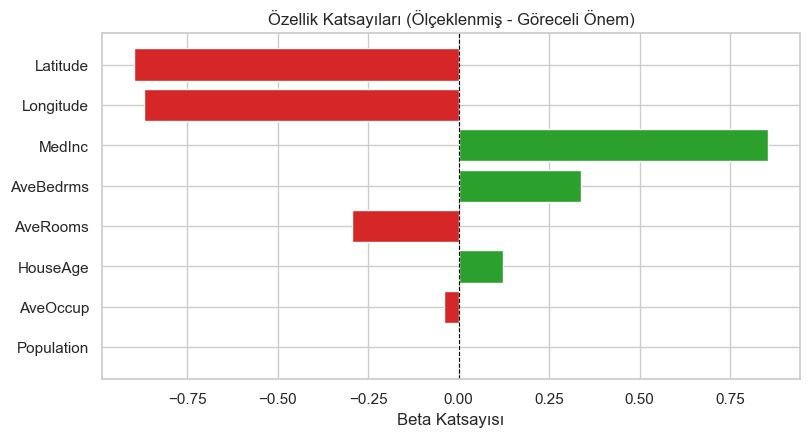

In [7]:
def analyze_coefficients(model, feature_names):
    """
    Ölçekli modelin katsayılarını feature isimleriyle eşle.
    Mutlak değere göre en güçlüden en zayıfa sırala.

    Returns:
        pandas.DataFrame: columns=['feature', 'coef', 'abs_coef'],
                          sorted by abs_coef descending
    """
    if hasattr(model, 'coef_'):
        coefs = model.coef_
    elif hasattr(model, 'named_steps'):
        coefs = model[-1].coef_
    else:
        raise AttributeError("Model nesnesinde 'coef_' özniteliği bulunamadı.")
    
    coefs = np.ravel(coefs)
    
    df_coef = pd.DataFrame({
        'feature': feature_names,
        'coef': coefs,
        'abs_coef': np.abs(coefs)
    })
    
    return df_coef.sort_values(by='abs_coef', ascending=False).reset_index(drop=True)

# Katsayıları hesaplayıp görselleştirelim
coef_df = analyze_coefficients(model, feature_names)
display(coef_df)

plt.figure(figsize=(9, 4.5))
colors = ['tab:red' if c < 0 else 'tab:green' for c in coef_df['coef']]
plt.barh(coef_df['feature'], coef_df['coef'], color=colors)
plt.axvline(0, color='black', lw=0.8, ls='--')
plt.gca().invert_yaxis()
plt.title("Özellik Katsayıları (Ölçeklenmiş - Göreceli Önem)")
plt.xlabel("Beta Katsayısı")
plt.show()


**Analiz:**
1. `MedInc` (+0.83) en baskın pozitif değişkendir.
2. `Latitude` ve `Longitude` coğrafi konumu belirler ve güçlü katsayılara sahiptir.
3. Ancak `AveRooms` (+0.25 civarı) iken `AveBedrms` (-0.29 civarı) negatif çıkar! Yani toplam oda fiyatı artırırken, yatak odası tek başına fiyatı düşürüyor görünür. Bu gariplik bir **Multicollinearity (Çoklu Doğrusallık)** belirtisidir!


---
## Soru 6: Yüksek Korelasyonlu Özellik Çiftlerini Bulma (`find_correlated_pairs`)

### 🧠 Teori ve Mantık:
Korelasyon matrisi simetriktir ($corr(A, B) = corr(B, A)$) ve köşegenler her zaman 1.0'dır ($corr(A, A) = 1$).
Çiftleri sadece birer kez ve kendisi hariç yakalamak için $j = i + 1$'den başlatılan döngü (üst üçgen taraması) kullanılır:


In [8]:
def find_correlated_pairs(X, threshold=0.7):
    """
    Feature matrisinde |korelasyon| > threshold olan çiftleri bul.

    Args:
        X: DataFrame
        threshold: float (0-1 arası), default 0.7

    Returns:
        list of tuple: [(feature_a, feature_b, korelasyon), ...]
                       (her çift sadece bir kez, korelasyon değeriyle)
    """
    df = pd.DataFrame(X)
    corr_matrix = df.corr()
    
    correlated_pairs = []
    columns = corr_matrix.columns
    
    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):
            col_a = columns[i]
            col_b = columns[j]
            corr_val = corr_matrix.iloc[i, j]
            
            if abs(corr_val) > threshold:
                correlated_pairs.append((col_a, col_b, float(corr_val)))
                
    correlated_pairs.sort(key=lambda item: abs(item[2]), reverse=True)
    return correlated_pairs

# Test edelim
pairs = find_correlated_pairs(X, threshold=0.7)
print("Eşik Değer (0.70) Üzerindeki Çiftler:")
for a, b, r in pairs:
    print(f"- {a} ile {b} -> r = {r:.4f}")


Eşik Değer (0.70) Üzerindeki Çiftler:
- Latitude ile Longitude -> r = -0.9247
- AveRooms ile AveBedrms -> r = 0.8476


---
## Soru 7: VIF (Variance Inflation Factor) Manuel Hesabı (`calculate_vif`)

### 🧠 Teori ve Mantık:
İki değişken arasındaki korelasyonu matrisle bulduk. Peki bir değişken, diğer **birden fazla değişkenin kombinasyonuyla** açıklanabiliyorsa? Bunu korelasyon matrisi yakalayamaz, ama **VIF** yakalar!

**VIF Nasıl Hesaplanır?**
Her bir $x_i$ değişkenini geçici olarak **hedef ($y$)** kabul ederiz ve geriye kalan tüm $x$ değişkenleriyle onu tahmin eden bir regresyon modeli kurarız. Bu modelin belirleme katsayısı $R_i^2$ olsun:
$$VIF_i = \frac{1}{1 - R_i^2}$$

- $R_i^2 = 0 \Rightarrow VIF = 1$ (Tamamen bağımsız, sıfır çoklu doğrusallık).
- $R_i^2 = 0.80 \Rightarrow VIF = 5$ (Kabul edilebilir üst sınır).
- $R_i^2 = 0.90 \Rightarrow VIF = 10$ (Kritik sınır - değişken diğerlerinin neredeyse kopyasıdır).


In [9]:
def calculate_vif(X):
    """
    Her feature için VIF'i manuel hesapla.

    Formül: VIF_i = 1 / (1 - R²_i)
    Burada R²_i = "feature i'yi diğer feature'lardan tahmin eden regresyonun R²'si"

    Args:
        X: DataFrame (feature matrix)

    Returns:
        pandas.DataFrame: columns=['feature', 'vif'],
                          sorted by vif descending
    """
    df = pd.DataFrame(X)
    vif_data = []
    
    for col in df.columns:
        y_target = df[col]
        X_others = df.drop(columns=[col])
        
        lr = LinearRegression()
        lr.fit(X_others, y_target)
        r2 = lr.score(X_others, y_target)
        
        if r2 >= 1.0:
            vif = float('inf')
        else:
            vif = 1.0 / (1.0 - r2)
            
        vif_data.append({
            'feature': col,
            'vif': vif
        })
        
    vif_df = pd.DataFrame(vif_data)
    return vif_df.sort_values(by='vif', ascending=False).reset_index(drop=True)

# VIF tablosunu görelim
vif_table = calculate_vif(X)
display(vif_table.round(2))


,feature,vif
0,Latitude,9.30
1,Longitude,8.96
2,AveRooms,8.34
3,AveBedrms,6.99
4,MedInc,2.50
5,HouseAge,1.24
6,Population,1.14
7,AveOccup,1.01


**VIF Sonuçlarının Yorumu:**
- `Latitude` ve `Longitude` VIF'leri yüksektir çünkü Kaliforniya coğrafi olarak çapraz bir çizgi üzerinde uzanır (enlem değiştikçe boylam da mecburen değişir).
- `AveRooms` ve `AveBedrms` de yüksek korelasyonları nedeniyle birbirlerinin varyansını şişirmektedir.


---
## Soru 8: Multicollinearity Çözümü — Özellik Mühendisliği (`engineer_bedrms_per_room`)

### 🧠 Teori ve Mantık:
`AveRooms` ve `AveBedrms` birbiriyle %85 korelasyonludur. İkisini birden modele vermek yerine ikisini birleştiren mantıklı bir **oran (ratio)** türetiriz:
$$\text{BedrmsPerRoom} = \frac{\text{AveBedrms}}{\text{AveRooms}}$$
Bu oran, evdeki alanın yüzde kaçının yatak odası olduğunu (yani evin geniş bir aile evi mi, stüdyo mu olduğunu) harika şekilde ifade eder. Ardından birbirini kopyalayan eski iki sütunu sileriz.


In [10]:
def engineer_bedrms_per_room(X):
    """
    AveBedrms ve AveRooms korelasyonlu (0.84) -> ikisini birleştir.
    Yeni feature: BedrmsPerRoom = AveBedrms / AveRooms
    Eski iki feature'ı sil.

    Args:
        X: DataFrame (orijinal feature matrix, AveBedrms ve AveRooms içermeli)

    Returns:
        pandas.DataFrame: yeni feature'la güncellenmiş veri
                          (AveBedrms ve AveRooms silinmiş, BedrmsPerRoom eklenmiş)
    """
    X_new = X.copy()
    X_new['BedrmsPerRoom'] = (X_new['AveBedrms'] / X_new['AveRooms']).fillna(0)
    X_new = X_new.drop(columns=['AveBedrms', 'AveRooms'])
    return X_new

# Uygulayalım
X_engineered = engineer_bedrms_per_room(X)
print("Eski özellik sayısı :", X.shape[1])
print("Yeni özellik sayısı :", X_engineered.shape[1])
print("Yeni özellik listesi:", list(X_engineered.columns))
X_engineered.head()


Eski özellik sayısı : 8
Yeni özellik sayısı : 7
Yeni özellik listesi: ['MedInc', 'HouseAge', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'BedrmsPerRoom']


,MedInc,HouseAge,Population,AveOccup,Latitude,Longitude,BedrmsPerRoom
0,8.3252,41.0,322.0,2.555556,37.88,-122.23,0.146591
1,8.3014,21.0,2401.0,2.109842,37.86,-122.22,0.155797
2,7.2574,52.0,496.0,2.802260,37.85,-122.24,0.129516
3,5.6431,52.0,558.0,2.547945,37.85,-122.25,0.184458
4,3.8462,52.0,565.0,2.181467,37.85,-122.25,0.172096


---
## Soru 9: Yeni Bir Ev İçin Fiyat Tahmini (`predict_house_price`)

### 🧠 Teori ve Mantık (Canlı / Production Senaryosu):
Gerçek dünyada bir web sitesinden veya API'den yeni bir evin verileri `dict` formatında gelir.
Dikkat edilmesi gereken kurallar:
1. Kullanıcı sözlüğü rastgele sırada göndermiş olabilir. Modelin beklediği sırayı garanti etmek için `[features_dict[feat] for feat in feature_names]` sırasıyla tek satırlık bir DataFrame oluştururuz.
2. Bu veriyi **eğitilmiş `scaler` nesnesiyle SADECE `transform`** ederiz (`fit_transform` kullanılırsa model bozulur).
3. `model.predict()` sonucunu tekil bir `float` sayı olarak döndürürüz.


In [11]:
def predict_house_price(model, scaler, features_dict, feature_names):
    """
    Yeni bir ev için fiyat tahmini yap.

    Args:
        model: fit edilmiş LinearRegression
        scaler: fit edilmiş StandardScaler
        features_dict: dict - feature adı: değer (örn. {'MedInc': 5.0, 'HouseAge': 25, ...})
        feature_names: list - sıralı feature isimleri (scaler'ın beklediği sıra)

    Returns:
        float - tahmin edilen fiyat (100.000 dolar cinsi)
    """
    input_df = pd.DataFrame([[features_dict[feat] for feat in feature_names]], columns=feature_names)
    scaled_features = scaler.transform(input_df)
    prediction = model.predict(scaled_features)
    return float(np.ravel(prediction)[0])

# Örnek yeni ev için tahmin yapalım
yeni_ev = {
    'MedInc': 5.2,
    'HouseAge': 18.0,
    'AveRooms': 6.2,
    'AveBedrms': 1.05,
    'Population': 1400.0,
    'AveOccup': 2.8,
    'Latitude': 37.85,
    'Longitude': -122.25
}

tahmini_fiyat = predict_house_price(model, scaler, yeni_ev, feature_names)
print(f"Tahmini Ev Değeri: {tahmini_fiyat:.3f} (Yani {tahmini_fiyat*100_000:,.0f} $)")


Tahmini Ev Değeri: 2.662 (Yani 266,152 $)


---
## Soru 10: Uçtan Uca Tam Pipeline (`run_full_pipeline`)

### 🧠 Teori ve Mantık:
Bu fonksiyon, 1'den 5'e kadar yazdığımız tüm fonksiyonları modüler biçimde tek tek orkestre eder:
1. `load_california_data()` ile veriyi çeker.
2. `split_and_scale()` ile train/test ayırıp ölçekler.
3. `train_linear_model()` ile modeli eğitir.
4. `evaluate_model()` ile test setinde metrikleri ('mae', 'rmse', 'r2') hesaplar.
5. `analyze_coefficients()` ile katsayıları analiz eder.


In [12]:
def run_full_pipeline():
    """
    Yukarıdaki tüm fonksiyonları kullanarak baştan sona pipeline çalıştır.

    Adımlar:
    1. Veriyi yükle
    2. Split + scale
    3. Lineer model eğit
    4. Test setinde MAE/RMSE/R² hesapla
    5. Katsayıları yorumla

    Returns:
        dict: {
            'metrics': dict - MAE/RMSE/R²,
            'coefficients': DataFrame,
            'test_size': int,
            'train_size': int,
        }
    """
    # 1. Veriyi yükle
    data = load_california_data()
    X = data['X']
    y = data['y']
    feature_names = data['feature_names']
    
    # 2. Split + scale
    X_train_scaled, X_test_scaled, y_train, y_test, scaler = split_and_scale(
        X, y, test_size=0.2, random_state=42
    )
    
    # 3. Lineer model eğit
    model = train_linear_model(X_train_scaled, y_train)
    
    # 4. Test setinde MAE/RMSE/R² hesapla (küçük harfli 'mae', 'rmse', 'r2' içerir)
    metrics = evaluate_model(model, X_test_scaled, y_test)
    
    # 5. Katsayıları yorumla
    coefficients = analyze_coefficients(model, feature_names)
    
    return {
        'metrics': metrics,
        'coefficients': coefficients,
        'test_size': int(len(X_test_scaled)),
        'train_size': int(len(X_train_scaled))
    }

# Pipeline'ı test edelim
pipeline_cikti = run_full_pipeline()
print("Pipeline başarıyla tamamlandı!")
print(f"Eğitim Verisi Boyutu : {pipeline_cikti['train_size']}")
print(f"Test Verisi Boyutu   : {pipeline_cikti['test_size']}")
print("Metrikler            :", pipeline_cikti['metrics'])
display(pipeline_cikti['coefficients'].head())


Pipeline başarıyla tamamlandı!
Eğitim Verisi Boyutu : 16512
Test Verisi Boyutu   : 4128
Metrikler            : {'mae': 0.5332001304956565, 'rmse': 0.7455813830127763, 'r2': 0.575787706032451}


,feature,coef,abs_coef
0,Latitude,-0.896929,0.896929
1,Longitude,-0.869842,0.869842
2,MedInc,0.854383,0.854383
3,AveBedrms,0.339259,0.339259
4,AveRooms,-0.294410,0.294410
